In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("KaggleV2-May-2016.csv")

print("=" * 60)
print("1. ORIGINAL DATASET")
print("=" * 60)

print("Original shape:", df.shape)

print("\nFirst five records:")
display(df.head())

print("\nOriginal column names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())



1. ORIGINAL DATASET
Original shape: (110527, 14)

First five records:


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No



Original column names:
['PatientId', 'AppointmentID', 'Gender', 'ScheduledDay', 'AppointmentDay', 'Age', 'Neighbourhood', 'Scholarship', 'Hipertension', 'Diabetes', 'Alcoholism', 'Handcap', 'SMS_received', 'No-show']

Missing values:
PatientId         0
AppointmentID     0
Gender            0
ScheduledDay      0
AppointmentDay    0
Age               0
Neighbourhood     0
Scholarship       0
Hipertension      0
Diabetes          0
Alcoholism        0
Handcap           0
SMS_received      0
No-show           0
dtype: int64

Duplicate records: 0


In [13]:
# Correct spelling of column names
df = df.rename(columns={
    "Hipertension": "Hypertension",
    "Handcap": "Handicap",
    "No-show": "No_show"
})

# Remove duplicate records
df = df.drop_duplicates().copy()

# Clean gender
df["Gender"] = (
    df["Gender"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Clean neighbourhood names
df["Neighbourhood"] = (
    df["Neighbourhood"]
    .astype(str)
    .str.strip()
)

# Convert age to numeric
df["Age"] = pd.to_numeric(
    df["Age"],
    errors="coerce"
)

# Convert date columns
for column in ["ScheduledDay", "AppointmentDay"]:
 df[column] = pd.to_datetime(
        df[column],
        errors="coerce",
        utc=True
    ).dt.tz_localize(None)

# Convert target column
# 0 = Attended
# 1 = No-show
df["No_show"] = (
    df["No_show"]
    .astype(str)
    .str.strip()
    .map({
        "No": 0,
        "Yes": 1
    })
)

# Remove missing important values
df = df.dropna(subset=[
    "Age",
    "ScheduledDay",
    "AppointmentDay",
    "No_show"
]).copy()

df["No_show"] = df["No_show"].astype(int)

print("\n" + "=" * 60)
print("2. BASIC CLEANING COMPLETED")
print("=" * 60)
print("Shape after basic cleaning:", df.shape)

print("\nCorrected column names:")
print(df.columns.tolist())

print("\nTarget distribution:")
print(df["No_show"].value_counts())

print("\nUpdated data types:")
print(
    df[
        [
            "Age",
            "ScheduledDay",
            "AppointmentDay",
            "No_show"
        ]
    ].dtypes
)



2. BASIC CLEANING COMPLETED
Shape after basic cleaning: (110527, 14)

Corrected column names:
['PatientId', 'AppointmentID', 'Gender', 'ScheduledDay', 'AppointmentDay', 'Age', 'Neighbourhood', 'Scholarship', 'Hypertension', 'Diabetes', 'Alcoholism', 'Handicap', 'SMS_received', 'No_show']

Target distribution:
No_show
0    88208
1    22319
Name: count, dtype: int64

Updated data types:
Age                        int64
ScheduledDay      datetime64[us]
AppointmentDay    datetime64[us]
No_show                    int64
dtype: object


In [14]:
# Calculate waiting period
df["WaitingDays"] = (
    df["AppointmentDay"].dt.normalize() -
    df["ScheduledDay"].dt.normalize()
).dt.days

negative_age = (df["Age"] < 0).sum()

invalid_dates = (
    df["WaitingDays"] < 0
).sum()

print("\n" + "=" * 60)
print("3. INCONSISTENT RECORDS")
print("=" * 60)

print("Negative age records:", negative_age)

print(
    "Appointments before scheduling:",
    invalid_dates
)

# Remove invalid records
df = df[
    (df["Age"] >= 0) &
    (df["WaitingDays"] >= 0)
].copy()


3. INCONSISTENT RECORDS
Negative age records: 1
Appointments before scheduling: 5


In [16]:
# Create age groups
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[
        -1,
        17,
        30,
        45,
        60,
        np.inf
    ],
    labels=[
        "0-17",
        "18-30",
        "31-45",
        "46-60",
        "61+"
    ]
)

# Create weekday variables
df["AppointmentWeekday"] = (
    df["AppointmentDay"].dt.day_name()
)

df["ScheduledWeekday"] = (
    df["ScheduledDay"].dt.day_name()
)

# Create waiting-time groups
df["WaitingGroup"] = pd.cut(
    df["WaitingDays"],
    bins=[
         -1,
        0,
        7,
        14,
        30,
        np.inf
    ],
    labels=[
        "Same day",
        "1-7 days",
        "8-14 days",
        "15-30 days",
        "31+ days"
    ]
)


In [20]:
df = df.sort_values([
    "PatientId",
    "AppointmentDay",
    "ScheduledDay"
]).copy()

patient_group = df.groupby(
    "PatientId",
    sort=False
)

df["PreviousAppointments"] = (
    patient_group.cumcount()
)

df["PreviousNoShows"] = (
    patient_group["No_show"].cumsum() -
    df["No_show"]
)

df["PreviousAttendance"] = (
    df["PreviousAppointments"] -
    df["PreviousNoShows"]
)

df["PreviousNoShowRate"] = np.where(
    df["PreviousAppointments"] > 0,

    df["PreviousNoShows"] /
    df["PreviousAppointments"],

    0
)
df["PreviousHistoryGroup"] = pd.cut(
    df["PreviousNoShowRate"],
    bins=[
        -0.01,
        0,
        0.25,
        0.50,
        0.75,
        1
    ],
    labels=[
        "0% / no history",
        "1-25%",
        "26-50%",
        "51-75%",
        "76-100%"
    ]
)



In [21]:
df["Status"] = df["No_show"].map({
    0: "Attended",
    1: "No-show"
})

df["SMS_Status"] = df["SMS_received"].map({
    0: "No SMS",
    1: "SMS received"
})

df["Scholarship_Status"] = df["Scholarship"].map({
    0: "No scholarship",
    1: "Scholarship"
})

In [22]:
print("\n" + "=" * 60)
print("4. FINAL CLEANED DATASET")
print("=" * 60)

print("Cleaned shape:", df.shape)

print(
    "Remaining missing values:",
    df.isnull().sum().sum()
)

print(
    "Remaining duplicate records:",
    df.duplicated().sum()
)

print(
    "Overall no-show rate: {:.2f}%".format(
        df["No_show"].mean() * 100
    )
)

print("\nAttendance distribution:")
print(df["Status"].value_counts())

print("\nFirst five cleaned records:")

display(
    df[
        [
            "Gender",
            "Age",
            "AgeGroup",
             "WaitingDays",
            "AppointmentWeekday",
            "SMS_received",
            "PreviousAppointments",
            "PreviousNoShows",
            "No_show"
        ]
    ].head()
)



4. FINAL CLEANED DATASET
Cleaned shape: (110521, 27)
Remaining missing values: 0
Remaining duplicate records: 0
Overall no-show rate: 20.19%

Attendance distribution:
Status
Attended    88207
No-show     22314
Name: count, dtype: int64

First five cleaned records:


,Gender,Age,AgeGroup,WaitingDays,AppointmentWeekday,SMS_received,PreviousAppointments,PreviousNoShows,No_show
100517,F,44,31-45,3,Friday,0,0,0,0
105430,M,39,31-45,0,Wednesday,0,0,0,0
3950,F,33,31-45,0,Wednesday,0,0,0,0
73303,M,12,0-17,3,Monday,0,0,0,0
73228,F,14,0-17,7,Friday,1,0,0,0


In [23]:
def no_show_summary(column):

    result = df.groupby(
        column,
        observed=False
    )["No_show"].agg(
        Appointments="size",
        NoShows="sum",
        NoShowRate="mean"
    )

    result["NoShowRate"] = (
        result["NoShowRate"] * 100
    ).round(2)

    return result


# Display EDA tables
eda_columns = [
    "AgeGroup",
    "AppointmentWeekday",
    "SMS_Status",
    "WaitingGroup",
    "Scholarship_Status",
    "PreviousHistoryGroup"
]

for column in eda_columns:

    print("\n" + "=" * 60)

    print(
     "NO-SHOW ANALYSIS BY",
        column.upper()
    )

    print("=" * 60)

    display(
        no_show_summary(column)
    )



NO-SHOW ANALYSIS BY AGEGROUP


,Appointments,NoShows,NoShowRate
AgeGroup,,,
0-17,27378,5996,21.90
18-30,18250,4491,24.61
31-45,21953,4691,21.37
46-60,23179,4131,17.82
61+,19761,3005,15.21



NO-SHOW ANALYSIS BY APPOINTMENTWEEKDAY


,Appointments,NoShows,NoShowRate
AppointmentWeekday,,,
Friday,19019,4037,21.23
Monday,22713,4689,20.64
Saturday,39,9,23.08
Thursday,17246,3337,19.35
Tuesday,25638,5150,20.09
Wednesday,25866,5092,19.69



NO-SHOW ANALYSIS BY SMS_STATUS


...

,Appointments,NoShows,NoShowRate
WaitingGroup,,,
Same day,38562,1792,4.65
1-7 days,32185,7772,24.15
8-14 days,12025,3664,30.47
15-30 days,17371,5661,32.59
31+ days,10378,3425,33.00



NO-SHOW ANALYSIS BY SCHOLARSHIP_STATUS


,Appointments,NoShows,NoShowRate
Scholarship_Status,,,
No scholarship,99660,19736,19.80
Scholarship,10861,2578,23.74



NO-SHOW ANALYSIS BY PREVIOUSHISTORYGROUP


,Appointments,NoShows,NoShowRate
PreviousHistoryGroup,,,
0% / no history,94556,17661,18.68
1-25%,3045,561,18.42
26-50%,5742,1578,27.48
51-75%,990,390,39.39
76-100%,6188,2124,34.32


In [26]:
def rate_plot(
    column,
    axis,
    title,
    order=None
):

    rates = df.groupby(
        column,
        observed=False
    )["No_show"].mean().mul(100)

    if order is not None:

        rates = (
            rates
            .reindex(order)
            .dropna()
        )

    sns.barplot(
        x=rates.index.astype(str),
        y=rates.values,
        ax=axis,
        color="steelblue"
    )

    axis.set_title(title)
    axis.set_xlabel("")
    axis.set_ylabel("No-show rate (%)")

    axis.tick_params(
        axis="x",
        rotation=30
    )

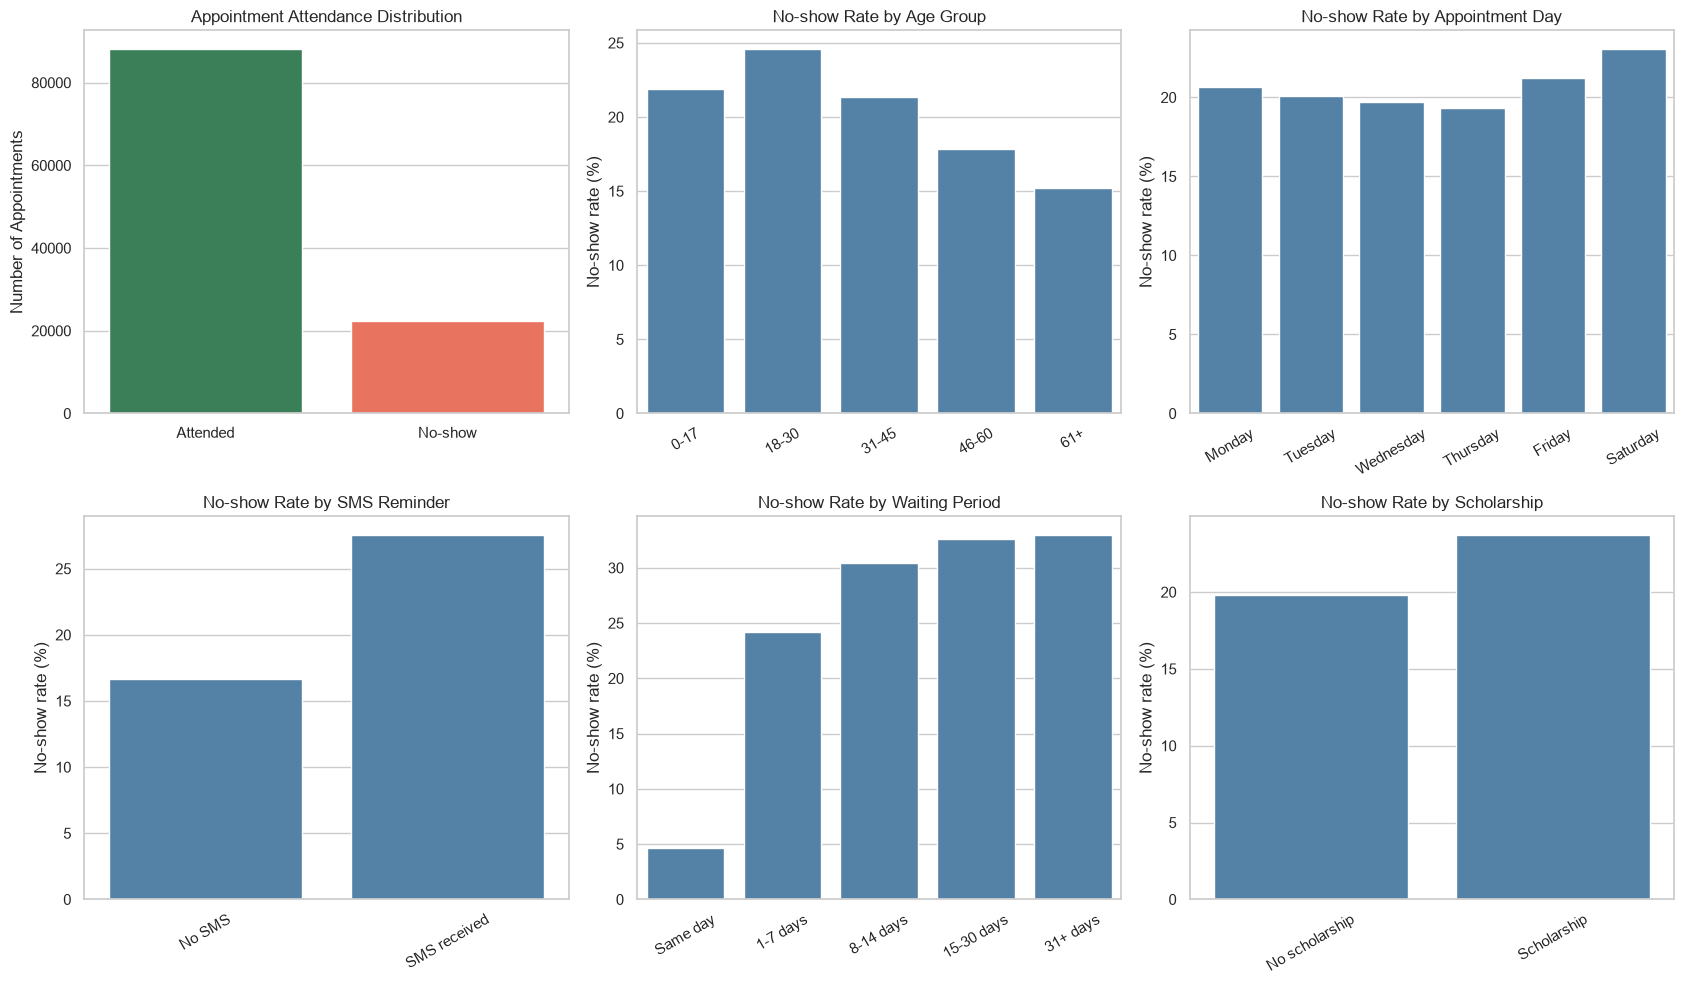

In [27]:
fig, axes = plt.subplots(
    2,
    3,
    figsize=(17, 10)
)

# Attendance distribution
sns.countplot(
    data=df,
    x="Status",
    order=[
        "Attended",
        "No-show"
    ],
    ax=axes[0, 0],
    palette=[
        "seagreen",
        "tomato"
    ]
)

axes[0, 0].set_title(
    "Appointment Attendance Distribution"
)

axes[0, 0].set_xlabel("")

axes[0, 0].set_ylabel(
    "Number of Appointments"
)

# Age-group graph
rate_plot(
    "AgeGroup",
    axes[0, 1],
    "No-show Rate by Age Group"
)
# Weekday graph
weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday"
]

rate_plot(
    "AppointmentWeekday",
    axes[0, 2],
    "No-show Rate by Appointment Day",
    weekday_order
)

# SMS graph
rate_plot(
    "SMS_Status",
    axes[1, 0],
    "No-show Rate by SMS Reminder"
)

# Waiting-period graph
rate_plot(
    "WaitingGroup",
    axes[1, 1],
    "No-show Rate by Waiting Period"
)

# Scholarship graph
rate_plot(
    "Scholarship_Status",
    axes[1, 2],
    "No-show Rate by Scholarship"
)
plt.tight_layout()
plt.show()



In [28]:
medical_conditions = [
    "Hypertension",
    "Diabetes",
    "Alcoholism",
    "Handicap"
]

condition_rates = pd.DataFrame({

    "Absent": [
        df.loc[
            df[condition] == 0,
            "No_show"
        ].mean() * 100

        for condition in medical_conditions
    ],

    "Present": [
        df.loc[
            df[condition] > 0,
            "No_show"
        ].mean() * 100

        for condition in medical_conditions
    ]

}, index=medical_conditions)

print("\n" + "=" * 60)
print("MEDICAL CONDITION ANALYSIS")
print("=" * 60)

display(
    condition_rates.round(2)
)



MEDICAL CONDITION ANALYSIS


,Absent,Present
Hypertension,20.90,17.30
Diabetes,20.36,18.00
Alcoholism,20.19,20.15
Handicap,20.23,18.09


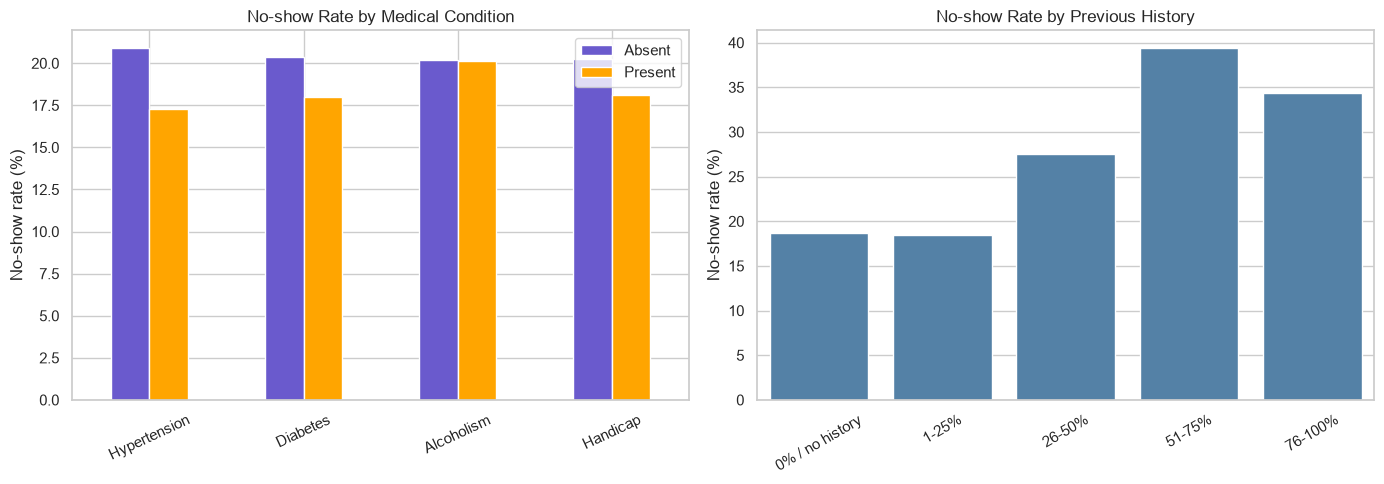

In [29]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

condition_rates.plot(
    kind="bar",
    ax=axes[0],
    color=[
        "slateblue",
        "orange"
    ]
)

axes[0].set_title(
    "No-show Rate by Medical Condition"
)

axes[0].set_xlabel("")

axes[0].set_ylabel(
    "No-show rate (%)"
)

axes[0].tick_params(
    axis="x",
    rotation=25
)

rate_plot(
    "PreviousHistoryGroup",
    axes[1],
    "No-show Rate by Previous History"
)

plt.tight_layout()
plt.show()

In [30]:
features = [
    "Gender",
    "Age",
    "Neighbourhood",
    "Scholarship",
    "Hypertension",
    "Diabetes",
    "Alcoholism",
    "Handicap",
    "SMS_received",
    "WaitingDays",
    "AppointmentWeekday",
    "ScheduledWeekday",
    "PreviousAppointments",
    "PreviousNoShows",
    "PreviousNoShowRate"
]

categorical_features = [
    "Gender",
    "Neighbourhood",
    "AppointmentWeekday",
    "ScheduledWeekday"
]

X = df[features]

y = df["No_show"]

print("\n" + "=" * 60)
print("MODEL DATA")
print("=" * 60)

print("X shape:", X.shape)
print("Y shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())


MODEL DATA
X shape: (110521, 15)
Y shape: (110521,)

Target values:
No_show
0    88207
1    22314
Name: count, dtype: int64


In [31]:
X_train, X_test, y_train, y_test = (
    train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
)

print("\nTraining records:", X_train.shape[0])

print("Testing records:", X_test.shape[0])



Training records: 88416
Testing records: 22105


In [32]:
preprocessing = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ],
    remainder="passthrough"
)



In [33]:
decision_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=6,
    min_samples_leaf=20,
    class_weight=None,
    random_state=42
)


# Complete model pipeline
final_model = Pipeline([
    (
        "preprocessing",
        preprocessing
    ),
    (
        "tree",
        decision_tree
    )
])

In [34]:
final_model.fit(
    X_train,
    y_train
)

print("\nDecision Tree trained successfully")


Decision Tree trained successfully


In [35]:
y_pred = final_model.predict(
    X_test
)

print("Predictions completed successfully")


Predictions completed successfully


In [36]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred
)

print("\n" + "=" * 60)
print("TUNED DECISION TREE RESULTS")
print("=" * 60)

print(
    "Accuracy : {:.2f}%".format(
        accuracy * 100
    )
)

print(
    "Precision: {:.2f}%".format(
        precision * 100
    )
)
print(
    "Recall   : {:.2f}%".format(
        recall * 100
    )
)

print(
    "F1-score : {:.2f}%".format(
        f1 * 100
    )
)



TUNED DECISION TREE RESULTS
Accuracy : 80.22%
Precision: 60.66%
Recall   : 5.80%
F1-score : 10.59%


In [37]:
print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Attended",
            "No-show"
        ],
        zero_division=0
    )
)



Classification Report:
              precision    recall  f1-score   support

    Attended       0.81      0.99      0.89     17642
     No-show       0.61      0.06      0.11      4463

    accuracy                           0.80     22105
   macro avg       0.71      0.52      0.50     22105
weighted avg       0.77      0.80      0.73     22105




Confusion Matrix:
[[17474   168]
 [ 4204   259]]


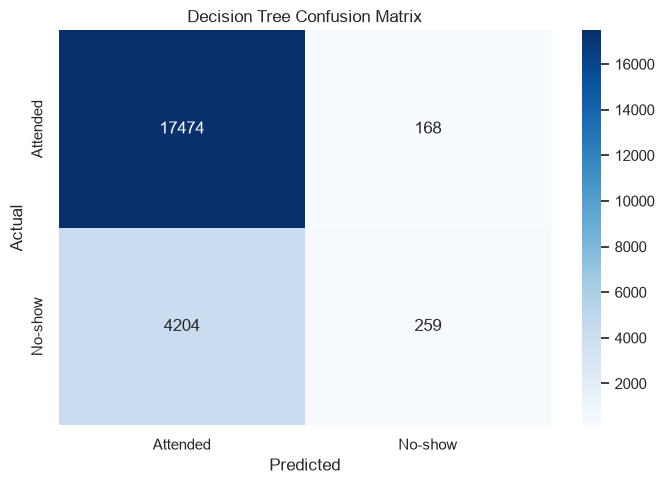

In [38]:
confusion = confusion_matrix(
    y_test,
    y_pred
)

print("\nConfusion Matrix:")

print(confusion)

plt.figure(figsize=(7, 5))

sns.heatmap(
    confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Attended",
        "No-show"
    ],
    yticklabels=[
        "Attended",
        "No-show"
    ]
)

plt.title(
    "Decision Tree Confusion Matrix"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()



TOP IMPORTANT FACTORS


,Importance
WaitingDays,0.715240
Age,0.111271
PreviousNoShowRate,0.076271
PreviousNoShows,0.035067
SMS_received,0.026924
Neighbourhood_GURIGICA,0.006701
Neighbourhood_SANTOS DUMONT,0.004792
PreviousAppointments,0.004739
Gender_F,0.004616
Neighbourhood_ITARARÉ,0.004271


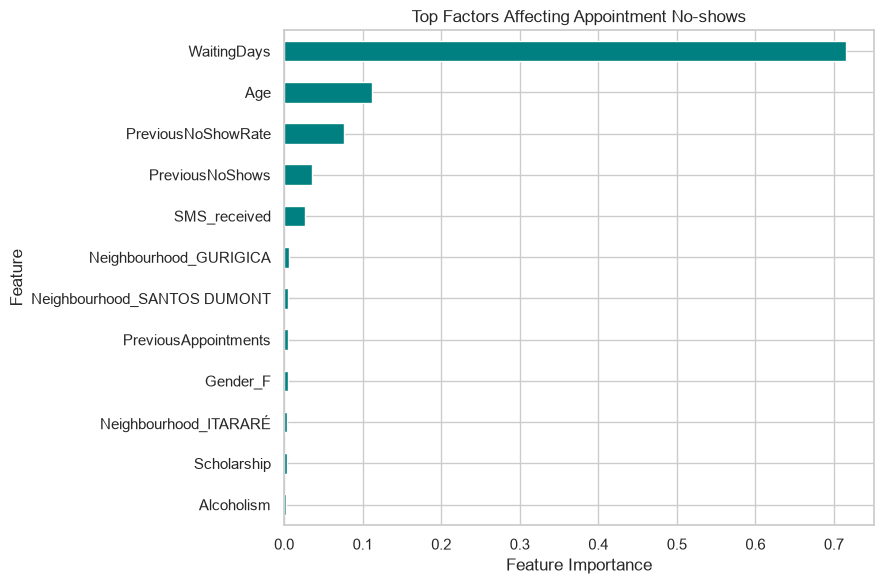

In [39]:
feature_names = (
    final_model
    .named_steps["preprocessing"]
    .get_feature_names_out()
)

feature_importance = pd.Series(

    final_model
    .named_steps["tree"]
    .feature_importances_,

    index=feature_names
)

feature_importance.index = (
    feature_importance.index
    .str.replace(
        "categorical__",
        "",
        regex=False
    )
    .str.replace(
        "remainder__",
        "",
        regex=False
    )
)

top_features = (
    feature_importance
    .sort_values(ascending=False)
    .head(12)
)

print("\n" + "=" * 60)
print("TOP IMPORTANT FACTORS")
print("=" * 60)
display(
    top_features.to_frame(
        "Importance"
    )
)

top_features.sort_values().plot(
    kind="barh",
    figsize=(9, 6),
    color="teal"
)

plt.title(
    "Top Factors Affecting Appointment No-shows"
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()



In [40]:
overall_rate = (
    df["No_show"].mean() * 100
)

same_day_rate = (
    df.loc[
        df["WaitingDays"] == 0,
        "No_show"
    ].mean() * 100
)

long_wait_rate = (
    df.loc[
        df["WaitingDays"] > 30,
        "No_show"
    ].mean() * 100
)

young_adult_rate = (
    df.loc[
        df["AgeGroup"] == "18-30",
        "No_show"
    ].mean() * 100
)

In [41]:
print("\n" + "=" * 60)
print("KEY INSIGHTS")
print("=" * 60)

print(
    f"1. Overall no-show rate: "
    f"{overall_rate:.2f}%"
)

print(
    f"2. Same-day no-show rate: "
    f"{same_day_rate:.2f}%"
)

print(
    f"3. Waiting over 30 days no-show rate: "
    f"{long_wait_rate:.2f}%"
)

print(
    f"4. Age 18-30 no-show rate: "
    f"{young_adult_rate:.2f}%"
)

print(
    "5. Waiting time, age and previous attendance "
    "history are important predictive factors."
)

print(
    "6. SMS status shows an association, but it "
    "does not prove that SMS causes no-shows."
)

print(
    "7. Medical conditions were weaker predictors "
    "than waiting time and patient history."
)



KEY INSIGHTS
1. Overall no-show rate: 20.19%
2. Same-day no-show rate: 4.65%
3. Waiting over 30 days no-show rate: 33.00%
4. Age 18-30 no-show rate: 24.61%
5. Waiting time, age and previous attendance history are important predictive factors.
6. SMS status shows an association, but it does not prove that SMS causes no-shows.
7. Medical conditions were weaker predictors than waiting time and patient history.


In [43]:
print("\n" + "=" * 60)
print("RECOMMENDATIONS")
print("=" * 60)

print(
    "1. Reduce long gaps between scheduling "
    "and appointment dates."
)

print(
    "2. Send reminders 24-48 hours before "
    "the appointment."
)

print(
    "3. Allow patients to confirm, cancel or "
    "reschedule appointments through SMS."
)

print(
    "4. Give additional reminders to patients "
    "with previous missed appointments."
)

print(
    "5. Maintain a waiting list to fill "
    "cancelled appointment slots."
)

print(
    "6. Prioritize appointments with long "
    "waiting periods."
)
print(
    "7. Validate the model before introducing "
    "selective overbooking."
)



RECOMMENDATIONS
1. Reduce long gaps between scheduling and appointment dates.
2. Send reminders 24-48 hours before the appointment.
3. Allow patients to confirm, cancel or reschedule appointments through SMS.
4. Give additional reminders to patients with previous missed appointments.
5. Maintain a waiting list to fill cancelled appointment slots.
6. Prioritize appointments with long waiting periods.
7. Validate the model before introducing selective overbooking.


In [44]:
print("\n" + "=" * 60)
print("FINAL RESULT")
print("=" * 60)

print(
    "The hospital appointment dataset was "
    "successfully cleaned and analysed. "
    "A Decision Tree classification model was "
    "developed to predict appointment no-shows. "
    "Waiting time, age and previous attendance "
    "history were identified as important factors."
)


FINAL RESULT
The hospital appointment dataset was successfully cleaned and analysed. A Decision Tree classification model was developed to predict appointment no-shows. Waiting time, age and previous attendance history were identified as important factors.
